In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
%matplotlib inline
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

In [4]:
df = pd.read_csv("Titanic-Dataset.csv")      # Titanic (Kaggle train.csv) - keep it in the same folder as this notebook
print("Rows:", df.shape[0], " Columns:", df.shape[1])
df.head()

Rows: 891  Columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
target = "Survived"
positive_class = 1                                  # 1 = survived
df["Sex_male"] = (df["Sex"] == "male").astype(int)  # encode Sex numerically
predictors = ["Pclass", "Sex_male", "Age", "SibSp", "Parch", "Fare"]
model_df = df[[target] + predictors].dropna()       # drops the rows with missing Age
print("Number of classes:", model_df[target].nunique())
X = model_df[predictors]
y = (model_df[target] == positive_class).astype(int)
print("Rows used:", len(model_df))
print("Class mapping: 1 = Survived | 0 = Did not survive")
print((y.value_counts(normalize=True)*100).round(2))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training:", len(X_train), " Testing:", len(X_test))

Number of classes: 2
Rows used: 714
Class mapping: 1 = Survived | 0 = Did not survive
Survived
0    59.38
1    40.62
Name: proportion, dtype: float64
Training: 571  Testing: 143


In [6]:
results, preds, probs = [], {}, {}
def evaluate(name, classifier):
    model = Pipeline([("scaler", StandardScaler()), ("classifier", classifier)])
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    probs[name] = model.predict_proba(X_test)[:, 1]
    results.append({"Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name], zero_division=0),
        "Recall": recall_score(y_test, preds[name], zero_division=0),
        "F1": f1_score(y_test, preds[name], zero_division=0),
        "AUC": roc_auc_score(y_test, probs[name])})
    print(name, {k: round(v, 4) for k, v in results[-1].items() if k != "Model"})
    return model

In [7]:
logistic = evaluate("Logistic Regression", LogisticRegression(max_iter=1000))
coef = logistic.named_steps["classifier"].coef_[0]
coef_table = pd.DataFrame({"Coefficient": coef, "Odds Ratio": np.exp(coef)}, index=predictors)
coef_table.round(4)

Logistic Regression {'Accuracy': 0.7972, 'Precision': 0.7458, 'Recall': 0.7586, 'F1': 0.7521, 'AUC': 0.8638}


,Coefficient,Odds Ratio
Pclass,-1.0412,0.3530
Sex_male,-1.2181,0.2958
Age,-0.6410,0.5268
SibSp,-0.3230,0.7240
Parch,-0.0132,0.9869
Fare,0.0668,1.0691


In [8]:
knn = evaluate("KNN (K=5)", KNeighborsClassifier(n_neighbors=5))

KNN (K=5) {'Accuracy': 0.7622, 'Precision': 0.7143, 'Recall': 0.6897, 'F1': 0.7018, 'AUC': 0.8113}


In [9]:
nb = evaluate("Gaussian Naive Bayes", GaussianNB())

Gaussian Naive Bayes {'Accuracy': 0.7692, 'Precision': 0.7049, 'Recall': 0.7414, 'F1': 0.7227, 'AUC': 0.8399}


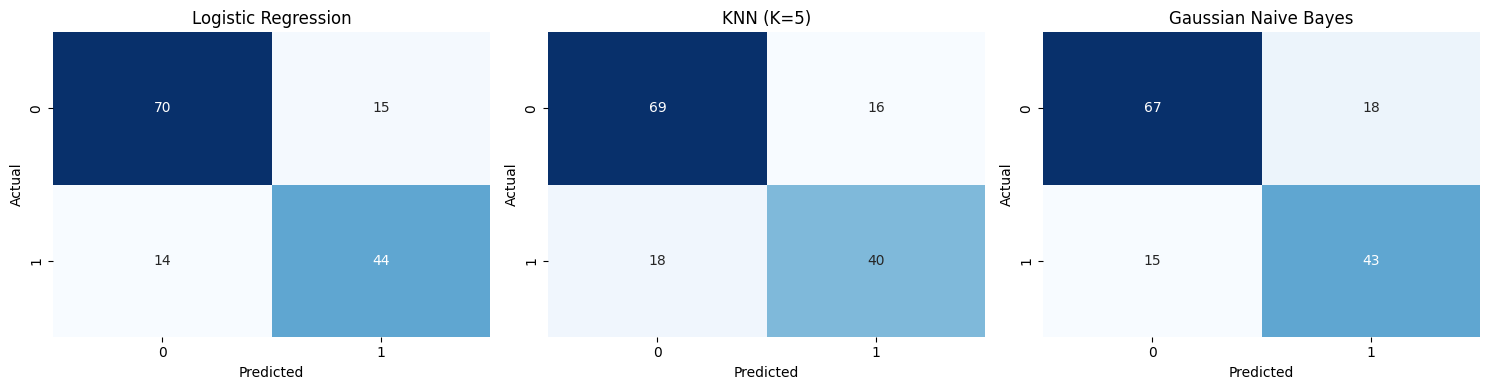

==================== Logistic Regression ====================
              precision    recall  f1-score   support

           0       0.83      0.82      0.83        85
           1       0.75      0.76      0.75        58

    accuracy                           0.80       143
   macro avg       0.79      0.79      0.79       143
weighted avg       0.80      0.80      0.80       143

==================== KNN (K=5) ====================
              precision    recall  f1-score   support

           0       0.79      0.81      0.80        85
           1       0.71      0.69      0.70        58

    accuracy                           0.76       143
   macro avg       0.75      0.75      0.75       143
weighted avg       0.76      0.76      0.76       143

==================== Gaussian Naive Bayes ====================
              precision    recall  f1-score   support

           0       0.82      0.79      0.80        85
           1       0.70      0.74      0.72        58

    a

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.show()
for name, pred in preds.items():
    print("="*20, name, "="*20)
    print(classification_report(y_test, pred, zero_division=0))

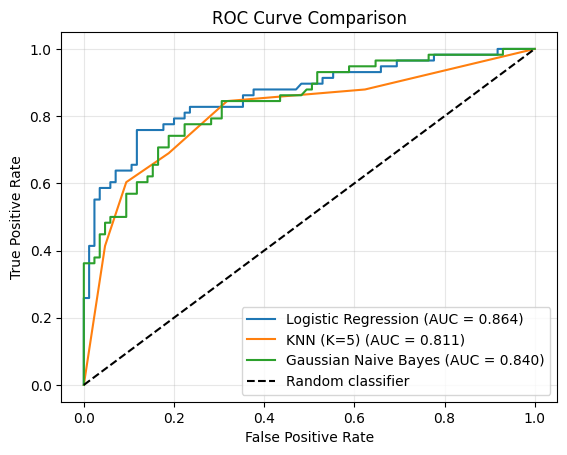

In [11]:
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison"); plt.legend(); plt.grid(alpha=0.3); plt.show()

,K,CV Accuracy,CV F1,CV AUC
0,1,0.7898,0.7435,0.7842
1,3,0.8126,0.7624,0.8449
2,5,0.8179,0.7679,0.8600
3,7,0.8003,0.7418,0.8627
4,9,0.8038,0.7502,0.8601
5,11,0.8038,0.7511,0.8567
6,15,0.8090,0.7598,0.8629


Best K by CV AUC: 15


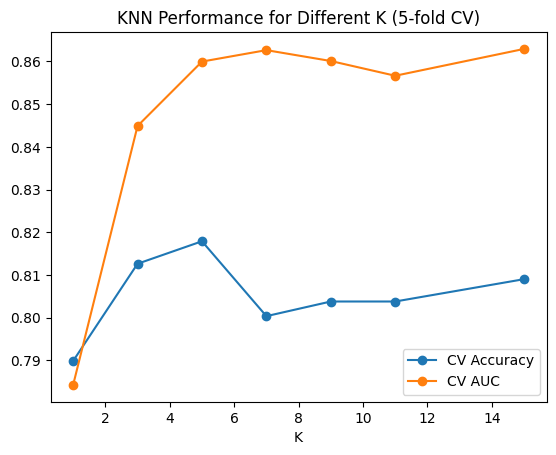

In [12]:
k_rows = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    pipe = Pipeline([("scaler", StandardScaler()), ("classifier", KNeighborsClassifier(n_neighbors=k))])
    cv = cross_validate(pipe, X_train, y_train, cv=5, scoring=["accuracy", "f1", "roc_auc"])
    k_rows.append({"K": k, "CV Accuracy": cv["test_accuracy"].mean(),
                   "CV F1": cv["test_f1"].mean(), "CV AUC": cv["test_roc_auc"].mean()})
knn_results = pd.DataFrame(k_rows)
display(knn_results.round(4))
print("Best K by CV AUC:", knn_results.loc[knn_results["CV AUC"].idxmax(), "K"])
knn_results.plot(x="K", y=["CV Accuracy", "CV AUC"], marker="o")
plt.title("KNN Performance for Different K (5-fold CV)"); plt.show()

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
Logistic Regression,0.7972,0.7458,0.7586,0.7521,0.8638
KNN (K=5),0.7622,0.7143,0.6897,0.7018,0.8113
Gaussian Naive Bayes,0.7692,0.7049,0.7414,0.7227,0.8399


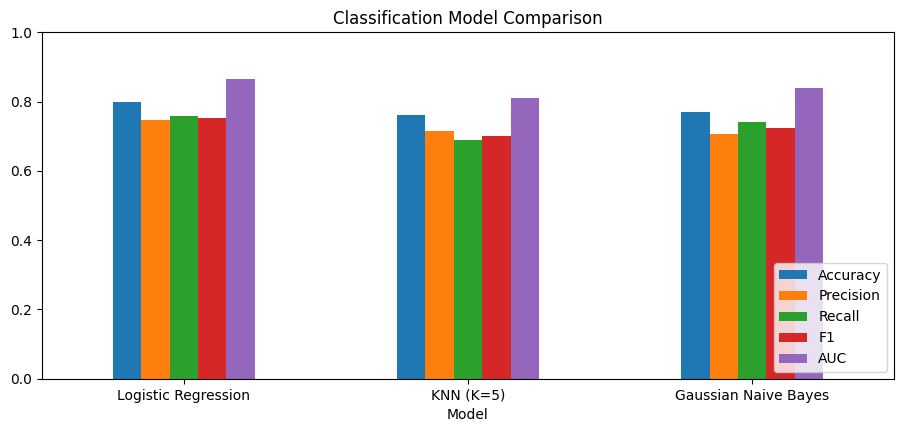

In [13]:
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))
comparison.plot(kind="bar", rot=0, figsize=(11, 4.5), ylim=(0, 1))
plt.title("Classification Model Comparison"); plt.legend(loc="lower right"); plt.show()
comparison.to_csv("Experiment_8_Classification_Results.csv")
coef_table.to_csv("Experiment_8_Logistic_Coefficients.csv")
knn_results.to_csv("Experiment_8_KNN_Results.csv", index=False)